# 🧪 9. Diseño experimental de la segunda entrega

La primera entrega terminó con un solo modelo (SVR lineal) que le ganaba a la persistencia pero casi empataba con el ingenuo estacional. En esta entrega se construye un **pipeline combinatorio**: cada modelo se combina con cada técnica de balanceo (solo en clasificación) y con cada método de optimización de hiperparámetros, y todas las combinaciones se evalúan con **validación cruzada anidada**.

Este capítulo fija las reglas del experimento **antes** de ver resultados: las tareas, la validación, los espacios de búsqueda, los optimizadores y las métricas.

In [1]:
import inspect

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from comun import estilo, SEED, AZUL, NARANJA, VERDE, GRIS, PALETA, fechas_eje
from datos import preparar, partir, folds_externos, folds_internos, X_COLS, UMBRAL_CAIDA
from modelos import ESPACIOS, REJILLAS, MODELOS_REG, MODELOS_CLF, BALANCEOS, OPTIMIZADORES
from optimizadores import PRESUPUESTO, GENETICO

estilo()
d = preparar()
train, test = partir(d)
print(f"train: {len(train):,} filas, {train['fecha'].nunique()} días ({train['fecha'].min():%d %b} – {train['fecha'].max():%d %b})")
print(f"test:  {len(test):,} filas, {test['fecha'].nunique()} días ({test['fecha'].min():%d %b} – {test['fecha'].max():%d %b})")
print(f"variables: {len(X_COLS)} -> {X_COLS}")

/opt/miniconda3/envs/ml_venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: 22,205 filas, 50 días (15 Jul – 02 Sep)
test:  9,304 filas, 21 días (03 Sep – 23 Sep)
variables: 14 -> ['lag1', 'lag7', 'lag14', 'media7', 'std7', 'nivel', 'part_efectivo', 'part_datafono', 'part_rumbo', 'part_mi_empresa', 'part_credito_clientes', 'dias_sin_venta7', 'festivo', 'dia_semana']


## 🎯 9.1 Las dos tareas

| Tarea | Objetivo | Pregunta de negocio |
|---|---|---|
| **Regresión** | `venta_total` del día siguiente (COP), modelada en $\log(1+y)$ | ¿Cuánto venderá mañana cada negocio? (igual que en la entrega 1) |
| **Clasificación** | `caida` = 1 si la venta de mañana es menor al **50 % de la mediana de los 7 días anteriores** | ¿Qué negocios tendrán mañana una caída fuerte (o no venderán)? |

La clasificación sale directamente del capítulo 4b: los días sin venta y las caídas son pocos, se concentran en negocios irregulares y **dominan el error** del modelo base. Una alerta de caída sirve para revisar el negocio (un cierre, una falla del POS, un problema de abastecimiento) antes de que pase.

**Por qué este umbral:**

- La referencia es la **mediana** de la semana anterior (no la media), para que un día anómalo de esa semana no mueva el umbral. Solo usa datos del pasado, así que no hay fuga.
- Con 50 % el evento es raro pero no tanto (3,7 % de train, 818 casos). Con "solo ceros" quedan 126 casos en 37 negocios: varios folds internos tendrían 10–20 positivos, muy pocos para comparar técnicas de balanceo. Con 70 %, el 11 % de los días serían "caídas" y la mayoría serían variaciones normales.
- Se fijó **antes** de entrenar cualquier modelo, a partir del EDA, y no se ajusta después.

In [2]:
balance = pd.DataFrame({
    "filas": [len(train), len(test)],
    "caídas": [train["caida"].sum(), test["caida"].sum()],
    "% caídas": [train["caida"].mean() * 100, test["caida"].mean() * 100],
    "de ellas sin venta": [(train.loc[train["caida"] == 1, "venta_total"] <= 0).sum(),
                           (test.loc[test["caida"] == 1, "venta_total"] <= 0).sum()],
}, index=["train", "test"])
balance["razón negativos : positivos"] = ((balance["filas"] - balance["caídas"]) / balance["caídas"]).map(lambda v: f"{v:.0f} : 1")
balance.round(2)

,filas,caídas,% caídas,de ellas sin venta,razón negativos : positivos
train,22205,818,3.68,103,26 : 1
test,9304,288,3.10,26,31 : 1


### Interpretación

- En train hay **818 caídas** (3,7 %, una cada 26 negocio-días) y en test **288** (3,1 %). El desbalance es fuerte pero no extremo: con SMOTE o ADASYN la clase positiva pasa de ~800 a ~21 000 casos sintéticos más reales.
- Solo 103 de las caídas de train (13 %) son días sin venta. La mayoría son días en que el negocio abrió pero vendió menos de la mitad de lo normal.
- Test tiene algo menos de caídas que train porque **no tiene festivos** (cap. 3), y los festivos cuadruplican la probabilidad de caída (cap. 4b).

## 🧮 9.2 El pipeline combinatorio

| Tarea | Modelos | Balanceo | Optimización | Total |
|---|---|---|---|---|
| Regresión | KNN, Ridge, Lasso, árbol, Random Forest, XGBoost, SVR | — (no aplica) | Grid, Random, Bayesiana (Optuna/TPE), Genética (DEAP) | 7 × 4 = **28** |
| Clasificación | KNN, Naive Bayes, logística L1/L2, árbol, Random Forest, XGBoost, SVM | ninguno, SMOTE, ADASYN, `class_weight='balanced'` | las mismas 4 | 7 × 4 × 4 = **112** |
| | | | | **140** |

Cada combinación se corre con una función parametrizada (`experimentos.correr`) dentro de un bucle sobre las 140 tuplas `(tarea, modelo, balanceo, optimizador)`, en paralelo con `joblib` (10 procesos, uno por núcleo). Cada resultado se guarda en su propio archivo y se resume en una **tabla maestra** (`resultados/maestra.csv`) con los hiperparámetros finales, las métricas del bucle externo (media y desviación), las métricas de test, los tiempos y la semilla.

**Cómo se aplica el balanceo en cada modelo:**

| Modelo | SMOTE / ADASYN | `balanced` |
|---|---|---|
| Logística, árbol, Random Forest, SVM | dentro del pipeline de `imblearn` | `class_weight='balanced'` |
| XGBoost | ídem | pesos de clase como `sample_weight` (equivale a `class_weight='balanced'`; XGBoost no tiene ese parámetro) |
| Naive Bayes | ídem | `priors=[0.5, 0.5]`: las dos clases pesan igual a priori |
| KNN | ídem | `KNNBalanceado`: divide la proporción de vecinos de cada clase por su frecuencia en train |

SMOTE y ADASYN van **después del escalado** (interpolan en el espacio de las variables) y dentro del `Pipeline` de `imblearn`, que solo los aplica en `fit`. Los datos de validación y de test **nunca** se remuestrean.

## 🪆 9.3 Validación cruzada anidada

Elegir hiperparámetros mirando el error de validación y reportar ese mismo error es optimista (se elige el que tuvo suerte). Por eso se separan dos niveles:

- **Bucle externo (4 folds)**: ventana creciente sobre los días de train, con 7 días de validación por fold. Solo se usa para **medir** el modelo ya optimizado. Las métricas de los capítulos 10, 12 y 13 vienen de aquí, como media ± desviación de los 4 folds.
- **Bucle interno (3 folds)**: dentro del train de cada fold externo, otra partición temporal con 4 días de validación por fold. Aquí corre la búsqueda completa (Grid, Random, Bayes o Genético).

**Por qué 4 × 3 y no más:** train tiene 50 días útiles (los primeros 14 se pierden por los rezagos). Cuatro semanas de validación externa cubren cada día de la semana 4 veces y dejan 22 días para el primer fold. Con 3 folds internos de 4 días, el train interno más chico tiene 10 días. Más folds dejarían trains de una semana.

**Por qué sin gap** (en la entrega 1 era de 7 días): con validación anidada, un gap de 7 en cada nivel deja el primer fold interno casi vacío. El gap no evita fuga, porque las variables ya solo usan el pasado (verificado en el cap. 5). Solo hacía la validación más pesimista que el uso real ($h = 1$).

Después de la validación anidada se repite la búsqueda **una vez más con todo train** (3 folds internos de 7 días), se reentrena y se predice el **test (3 – 23 sep)**. El test se usa solo para los análisis de residuos, calibración, interpretabilidad y las pruebas sobre predicciones (cap. 12–14), nunca para elegir.

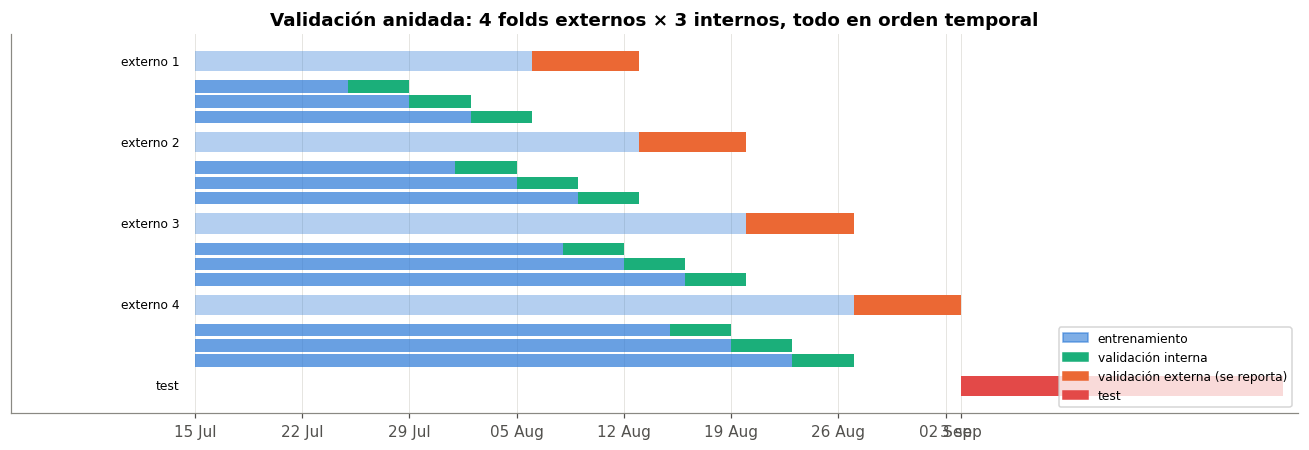

In [3]:
fechas = train["fecha"]
dias = np.sort(fechas.unique())
fig, ax = plt.subplots(figsize=(12, 4.2))
y = 0
for k, (tr, va) in enumerate(folds_externos(fechas)):
    f_tr, f_va = np.sort(fechas.iloc[tr].unique()), np.sort(fechas.iloc[va].unique())
    ax.barh(y, len(f_tr), left=0, color=AZUL, alpha=0.35, height=0.8)
    ax.barh(y, len(f_va), left=np.searchsorted(dias, f_va[0]), color=NARANJA, height=0.8)
    ax.text(-1, y, f"externo {k + 1}", ha="right", va="center", fontsize=8)
    y -= 1
    for j, (itr, iva) in enumerate(folds_internos(fechas.iloc[tr])):
        g_tr = np.sort(fechas.iloc[tr].iloc[itr].unique()); g_va = np.sort(fechas.iloc[tr].iloc[iva].unique())
        ax.barh(y, len(g_tr), left=0, color=AZUL, alpha=0.7, height=0.5)
        ax.barh(y, len(g_va), left=np.searchsorted(dias, g_va[0]), color=VERDE, height=0.5)
        y -= 0.6
    y -= 0.4
ax.barh(y, 21, left=len(dias), color="#e34948", height=0.8)
ax.text(-1, y, "test", ha="right", va="center", fontsize=8)
ax.set_yticks([])
ticks = list(range(0, len(dias), 7)) + [len(dias)]
ax.set_xticks(ticks)
ax.set_xticklabels([pd.Timestamp(dias[t]).strftime("%d %b") if t < len(dias) else "3 sep" for t in ticks])
ax.set_xlim(-12, len(dias) + 22)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, alpha=0.6, label="entrenamiento"), Patch(color=VERDE, label="validación interna"),
                   Patch(color=NARANJA, label="validación externa (se reporta)"), Patch(color="#e34948", label="test")],
          loc="lower right", fontsize=8)
ax.set_title("Validación anidada: 4 folds externos × 3 internos, todo en orden temporal")
plt.tight_layout()

In [4]:
# positivos de la clase "caída" en cada fold externo: tiene que haber suficientes para medir F1
filas = []
for k, (tr, va) in enumerate(folds_externos(fechas)):
    filas.append({"fold externo": k + 1, "días train": fechas.iloc[tr].nunique(),
                  "caídas en train": int(train["caida"].iloc[tr].sum()),
                  "validación": f"{fechas.iloc[va].min():%d %b} – {fechas.iloc[va].max():%d %b}",
                  "caídas en validación": int(train["caida"].iloc[va].sum())})
pd.DataFrame(filas).set_index("fold externo")

,días train,caídas en train,validación,caídas en validación
fold externo,,,,
1,22,323,06 Aug – 12 Aug,166
2,29,489,13 Aug – 19 Aug,161
3,36,650,20 Aug – 26 Aug,89
4,43,739,27 Aug – 02 Sep,79


### Interpretación

- El primer fold externo entrena con 22 días y el último con 43. Cada fold de validación tiene entre 79 y 166 caídas, suficientes para estimar el F1 con algo de estabilidad.
- Los folds 1 y 2 tienen el doble de caídas que los 3 y 4: contienen los festivos del 7 y del 17 de agosto. Por eso las métricas de clasificación **varían bastante entre folds**, y por eso se reportan como media ± desviación y no como un único número.

## 🗺️ 9.4 Espacios de búsqueda

Los rangos se fijaron con lo que se sabe del problema (~20 mil filas de train, 19 columnas, objetivo en log) y con lo aprendido en la entrega 1, no de forma arbitraria. Los hiperparámetros que varían en órdenes de magnitud ($C$, $\alpha$, *learning rate*, `min_samples_leaf`) se buscan en **escala logarítmica**.

| Modelo | Hiperparámetro | Rango | Por qué |
|---|---|---|---|
| KNN | `n_neighbors` | 5 – 200 (log) | Con 20 mil filas, menos de 5 vecinos es casi memorizar; más de 200 promedia negocios de tamaños muy distintos |
| | `weights` | uniforme / distancia | Si los vecinos cercanos deben pesar más |
| Ridge | $\alpha$ | $10^{-3}$ – $10^{3}$ (log) | De casi OLS a regularización fuerte; el VIF alto (cap. 4) sugiere que algo de regularización ayuda |
| Lasso | $\alpha$ | $10^{-5}$ – $10^{-1}$ (log) | Con $\alpha \geq 0{,}1$ en log todas las variables se anulan |
| Naive Bayes | `var_smoothing` | $10^{-12}$ – $10^{-2}$ (log) | Suaviza varianzas casi nulas (dummies, participaciones constantes) |
| Logística | $C$ | $10^{-3}$ – $10^{2}$ (log) | Inverso de la regularización |
| | penalización | L1 / L2 | L1 selecciona variables, L2 reparte el peso entre las colineales |
| Árbol | `max_depth` | 3 – 20 | Con más de 20 niveles cada hoja tiene pocos negocio-días |
| | `min_samples_leaf` | 1 – 300 (log) | Controla el sobreajuste mejor que la profundidad |
| Random Forest | `n_estimators` | 50 – 150 | El error se estabiliza rápido; más árboles solo cuestan tiempo (cap. 11) |
| | `max_depth`, `min_samples_leaf` | 5 – 20, 1 – 100 (log) | Como en el árbol |
| | `max_features` | 0,2 – 0,7 | Decorrelaciona los árboles; las variables de nivel son muy colineales |
| XGBoost | `n_estimators` | 100 – 500 | Junto con el *learning rate* fija la capacidad total |
| | `learning_rate` | 0,01 – 0,3 (log) | Rango estándar; menos de 0,01 necesitaría miles de árboles |
| | `max_depth` | 3 – 10 | Interacciones de hasta 10 variables |
| | `subsample`, `colsample_bytree` | 0,6 – 1 | Muestreo de filas y columnas (regulariza) |
| | `min_child_weight` | 1 – 50 (log) | Peso mínimo por hoja |
| SVR lineal | $C$ | $10^{-3}$ – 1 (log) | En la entrega 1 la superficie era plana para $C \geq 0{,}03$ |
| | $\epsilon$ | 0 – 0,5 | Ancho del tubo en log (0,5 ≈ ignorar errores de 50 %) |
| SVM lineal | $C$ | $10^{-4}$ – 10 (log) | Inverso de la regularización |

**SVM y SVR con núcleo lineal** (`LinearSVC`, `LinearSVR`) y no RBF: el SVM con núcleo cuesta entre $O(n^2)$ y $O(n^3)$ en entrenamiento y con 20 mil filas × 140 combinaciones × validación anidada no es viable. El capítulo 11 mide ese costo.

En **Random Forest** cada árbol se entrena con la mitad de las filas (`max_samples=0.5`). Hace a los árboles más distintos entre sí y reduce el tiempo a la mitad.

In [5]:
filas = []
for m, dims in ESPACIOS.items():
    for dim in dims:
        rango = dim[2] if dim[1] == "cat" else f"{dim[2]:g} – {dim[3]:g}" + (" (log)" if dim[4] else "")
        filas.append({"modelo": m, "hiperparámetro": dim[0], "tipo": dim[1], "rango": rango,
                      # lo que no está en la rejilla queda en el valor por defecto del modelo
                      "puntos en la rejilla": len(REJILLAS[m].get(dim[0], [None]))})
espacios = pd.DataFrame(filas)
espacios["tamaño de la rejilla"] = espacios["modelo"].map(lambda m: int(np.prod([len(v) for v in REJILLAS[m].values()])))
espacios.set_index(["modelo", "hiperparámetro"])

tipo                rango  puntos en la rejilla  \
modelo    hiperparámetro                                                       
knn       n_neighbors         int        5 – 200 (log)                     6   
          weights             cat  [uniform, distance]                     2   
ridge     alpha             float   0.001 – 1000 (log)                    16   
lasso     alpha             float    1e-05 – 0.1 (log)                    16   
nb        var_smoothing     float   1e-12 – 0.01 (log)                    16   
logistica C                 float    0.001 – 100 (log)                     8   
          penalty             cat             [l1, l2]                     2   
arbol     max_depth           int               3 – 20                     4   
          min_samples_leaf    int        1 – 300 (log)                     4   
rf        n_estimators        int             50 – 150                     2   
          max_depth           int               5 – 20                     2   
          min_samples_leaf    int        1 – 100 (log)                     2   
          max_features      float            0.2 – 0.7                     2   
xgb       n_estimators        int            100 – 500                     2   
          learning_rate     float     0.01 – 0.3 (log)                     2   
          max_depth           int               3 – 10                     2   
          subsample         float              0.6 – 1                     2   
          colsample_bytree  float              0.6 – 1                     1   
          min_child_weight  float         1 – 50 (log)                     1   
svr       C                 float      0.001 – 1 (log)                     8   
          epsilon           float              0 – 0.5                     2   
svm       C                 float    0.0001 – 10 (log)                    16   

                            tamaño de la rejilla  
modelo    hiperparámetro                          
knn       n_neighbors                         12  
          weights                             12  
ridge     alpha                               16  
lasso     alpha                               16  
nb        var_smoothing                       16  
logistica C                                   16  
          penalty                             16  
arbol     max_depth                           16  
          min_samples_leaf                    16  
rf        n_estimators                        16  
          max_depth                           16  
          min_samples_leaf                    16  
          max_features                        16  
xgb       n_estimators                        16  
          learning_rate                       16  
          max_depth                           16  
          subsample                           16  
          colsample_bytree                    16  
          min_child_weight                    16  
svr       C                                   16  
          epsilon                             16  
svm       C                                   16

## 🔍 9.5 Los cuatro métodos de optimización

Todos usan **la misma función de evaluación** (`optimizadores.evaluar_config`). En cada evaluación se arma un pipeline nuevo (imputación, escalado, one-hot, balanceo y modelo) y se ajusta **en cada fold interno solo con su train**. Así no hay fuga en ningún método, incluidos Optuna y DEAP, que no traen esto incorporado.

Todos tienen **el mismo presupuesto: 16 evaluaciones por búsqueda** (cada una son 3 ajustes, uno por fold interno). Así la comparación es de **calidad por unidad de presupuesto**. El capítulo 10 repite la comparación con presupuestos mayores.

| Método | Cómo propone el siguiente punto | Detalles |
|---|---|---|
| **Grid** | Recorre una rejilla fija | Rejillas de a lo sumo 16 puntos (tabla anterior). En los modelos con 4–6 hiperparámetros la rejilla tiene solo 2 valores por dimensión: es el problema de la maldición de la dimensión |
| **Random** | Muestrea cada hiperparámetro al azar, uniforme (o log-uniforme) en su rango | Bergstra y Bengio (2012): si pocos hiperparámetros importan, el azar prueba más valores distintos de esos que una rejilla |
| **Bayesiana (Optuna)** | Modelo sustituto + función de adquisición | Ver abajo |
| **Genética (DEAP)** | Población que evoluciona por selección, cruce y mutación | Ver abajo |

### Optimización bayesiana: TPE

- **Modelo sustituto: Tree-structured Parzen Estimator (TPE)**, el de Optuna. En lugar de modelar $p(\text{pérdida} \mid x)$ con un proceso gaussiano, separa las evaluaciones en "buenas" (el mejor 25 % aprox.) y "malas" y estima dos densidades con kernels: $\ell(x) = p(x \mid \text{bueno})$ y $g(x) = p(x \mid \text{malo})$. Maneja bien variables categóricas y enteras (por ejemplo `weights` o `penalty`) y su costo crece lineal con el número de evaluaciones (un proceso gaussiano crece cúbico).
- **Función de adquisición: mejora esperada (EI).** Bergstra et al. (2011) muestran que, con TPE, maximizar la EI equivale a maximizar $\ell(x)/g(x)$. Optuna genera 24 candidatos de $\ell(x)$ y elige el de mayor cociente.
- **Exploración vs. explotación:** la EI premia tanto los puntos con pérdida esperada baja (explotación) como los puntos inciertos que podrían ser mucho mejores (exploración). En TPE el balance lo dan el ancho de los kernels y las **5 primeras evaluaciones al azar** (`n_startup_trials=5`), que exploran antes de que el modelo tenga datos. Con 16 evaluaciones, 5 al azar es ~30 % de exploración pura.

### Algoritmo genético (DEAP)

In [6]:
pd.Series(GENETICO, name="valor").to_frame()

,valor
poblacion,6.00
elite,1.00
torneo,3.00
p_cruce,0.70
alfa_cruce,0.50
p_mutacion,0.30
sigma,0.15
indpb,0.50


- **Codificación:** cada individuo es un vector de genes en $[0, 1]$, uno por hiperparámetro, y se decodifica al rango real (en log si corresponde; las categorías se reparten en intervalos iguales).
- **Selección por torneo ($k = 3$):** se sacan 3 individuos al azar y gana el de menor pérdida. Comparado con la ruleta, no depende de la escala de la pérdida (en log o en 1 − F1 los valores son parecidos y la ruleta casi no discriminaría). Con $k = 3$ la presión de selección es moderada.
- **Cruce blend (BLX-α, $\alpha = 0{,}5$, probabilidad 0,7):** cada gen hijo se sortea en un intervalo que extiende en 50 % el segmento entre los genes de los padres. Así puede explorar un poco **fuera** de lo que tienen los padres, lo que es útil en espacios continuos.
- **Mutación gaussiana ($\sigma = 0{,}15$, probabilidad 0,3 por individuo y 0,5 por gen):** suma ruido normal y luego recorta a $[0, 1]$. $\sigma = 0{,}15$ es 15 % del rango, un salto mediano.
- **Elitismo (1 individuo):** el mejor de cada generación pasa intacto, así el mejor valor nunca empeora.
- **Población: 6.** Con 16 evaluaciones caben la población inicial y 2 generaciones (6 + 5 + 5). Es una población chica, que se justifica por el presupuesto igualado. El capítulo 10 corre el genético con 60 evaluaciones y mide la **diversidad** de la población (distancia media entre individuos) por generación, como indicador de convergencia prematura.
- Solo se evalúan los hijos que **cambiaron** (los copiados sin cruce ni mutación conservan su pérdida), para no gastar presupuesto en repetidos.

### Multi-fidelidad (Successive Halving)

Además de los 4 métodos, en el capítulo 10 se prueba **Successive Halving** (`HalvingRandomSearchCV`) en XGBoost y Random Forest. Empieza con muchas configuraciones y poco presupuesto (pocos árboles) y en cada ronda se queda con el mejor tercio (factor $\eta = 3$), al que le triplica el presupuesto. La fidelidad es el **número de árboles**: un bosque o un boosting con pocos árboles ya ordena bien las configuraciones (las malas son malas desde el principio), y el costo crece lineal con los árboles.

## 📏 9.6 Métrica de validación de cada tarea

**Regresión: RMSE en $\log(1+y)$**, la misma de la entrega 1. Es un error **relativo**, así que trata igual a negocios de 0,5 M y de 50 M COP/día. El RMSE en COP lo dominarían las 90 EDS. Además se reportan el **RMSE y el MAE en COP** (los pide el enunciado), el MAE en log, el WAPE y el R².

**Clasificación: F1 de la clase "caída".** Es la media armónica de *precision* y *recall* de la clase positiva:

- **No la accuracy:** con 3,7 % de positivos, decir siempre "no hay caída" da 96 % de accuracy y no sirve para nada.
- **Por qué no solo el recall:** el costo de un falso negativo (no avisar de una caída) es más alto que el de un falso positivo (revisar un negocio que estaba bien), pero una alerta que avisa en todos los negocios todos los días no se usa. El F1 obliga a que los dos sean razonables.
- **Por qué no el AUC para elegir:** el AUC mide solo el **orden** de los puntajes. El balanceo cambia sobre todo el **umbral efectivo** (cuántos casos quedan sobre 0,5), y eso es justo lo que se quiere comparar. El F1 se calcula con la clase predicha, así que el efecto del balanceo se ve. El AUC, la precisión promedio (AP) y el Brier se reportan igual.

## 🔁 9.7 Reproducibilidad

- **Semilla única** `SEED = 42` (en `comun.py`). Se pasa a numpy, a todos los modelos de scikit-learn y XGBoost (`random_state`), a SMOTE/ADASYN, al muestreador TPE de Optuna, al muestreo aleatorio y al genético (que usa `random.Random(semilla)` y además fija la semilla de `random`, porque DEAP usa el módulo global).
- **Entorno fijado:** `requirements.txt` con las versiones exactas (Python 3.9).
- **Código modular**, con docstrings estilo NumPy en toda función compartida:

| Módulo | Contenido |
|---|---|
| `comun.py` | Fechas, variables (rezagos, medias móviles), estilo de gráficos (entrega 1) |
| `datos.py` | Objetivo de clasificación, partición train/test, folds externos e internos |
| `modelos.py` | Los 14 modelos, espacios de búsqueda, rejillas y pipelines con balanceo |
| `optimizadores.py` | Grid, Random, Bayes (TPE) y Genético con la misma función de evaluación |
| `metricas.py` | Métricas de regresión y clasificación, ECE |
| `estadistica.py` | Friedman, Nemenyi, DeLong, Diebold-Mariano, Clark-West, Giacomini-White, MCS, bootstrap |
| `experimentos.py` | Bucle de las 140 combinaciones, validación anidada y tabla maestra |

La función central de la validación anidada:

In [7]:
import experimentos
print(inspect.getsource(experimentos.correr))

def correr(tarea, nombre, balanceo, metodo, train, test, semilla=SEED):
    """Validación anidada de una combinación + ajuste final y predicción en test.

    Bucle externo: 4 folds de 7 días (``folds_externos``). En cada uno se corre la
    búsqueda completa con 3 folds internos sobre el train de ese fold, se reentrena
    con los mejores hiperparámetros y se mide en la validación externa (esta es la
    métrica que se reporta). Al final se repite la búsqueda con todo train y se
    predice el test (3-23 sep), que solo se usa para los análisis de los cap. 12-14.

    Returns
    -------
    dict
        Resultados completos (historiales, predicciones, métricas y tiempos).
    """
    objetivo = "venta_total" if tarea == "reg" else "caida"
    X, y = train[X_COLS], train[objetivo].to_numpy()
    t0 = time.perf_counter()
    res = {"tarea": tarea, "modelo": nombre, "balanceo": balanceo, "optimizador": metodo,
           "semilla": semilla, "folds": [], "pred_val": []}

    for k, (tr, v